11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Размер обучающей выборки: (50000, 28, 28, 1)
Размер валидационной выборки: (10000, 28, 28, 1)
Размер тестовой выборки: (10000, 28, 28, 1)


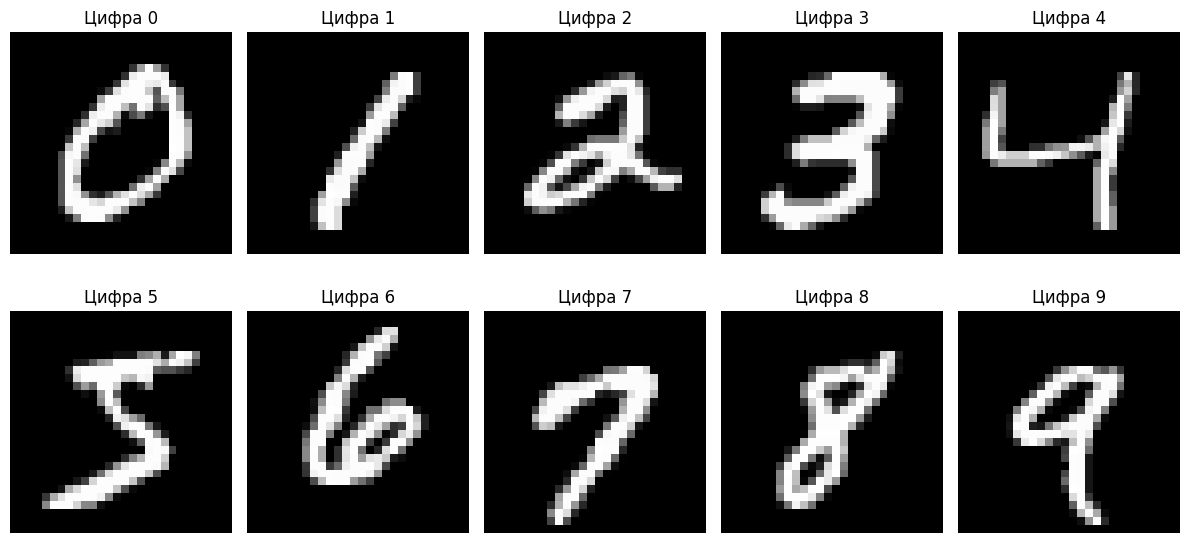

Форма X: (60000, 784)
Форма y: (60000,)
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]
Сумма собственных значений (my):      43.56
Сумма собственных значений (sklearn): 43.55
Форма Y_my: (1000, 50)
Форма Y_sk: (1000, 50)
Средняя разница по абсолютным значениям: 0.002870


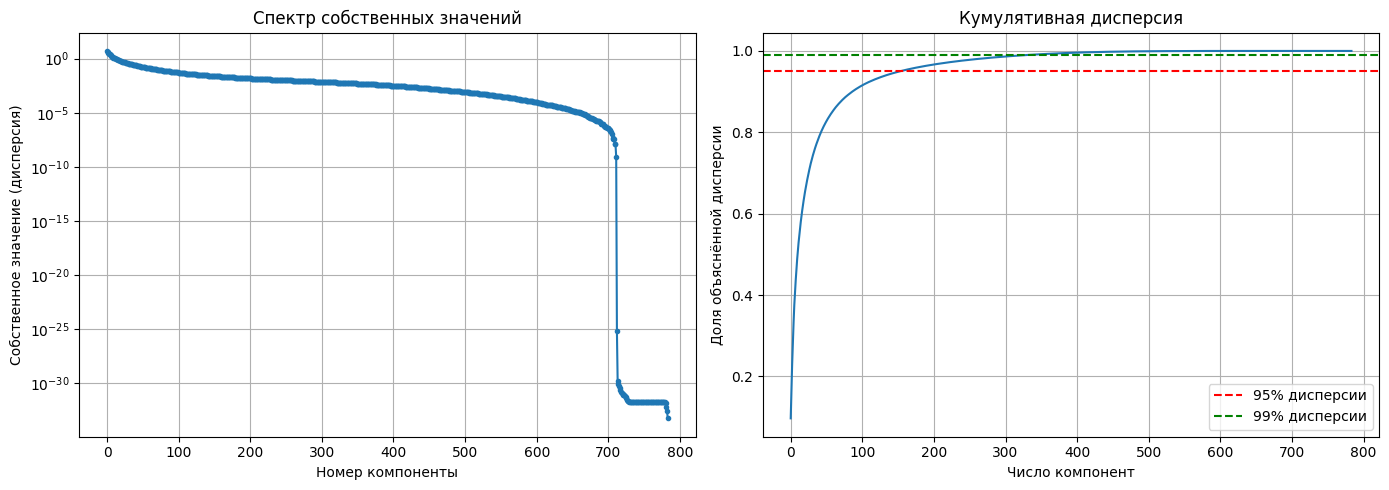

Доля дисперсии 15 компонент: 0.5793
Компонент для 95%: 154
Компонент для 99%: 331


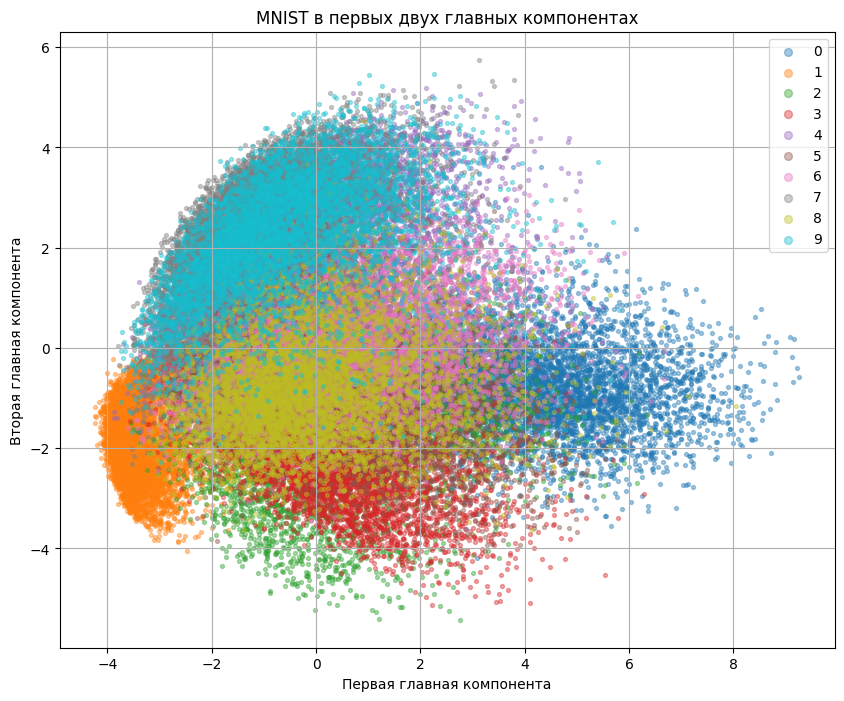

Точность my_kNN: 0.9485
Точность sklearn kNN: 0.9485
Разница: 0.0000
k=  1: accuracy=0.9510
k=  3: accuracy=0.9500
k=  5: accuracy=0.9485
k=  7: accuracy=0.9445
k= 10: accuracy=0.9440
k= 15: accuracy=0.9390
k= 20: accuracy=0.9350
k= 30: accuracy=0.9300


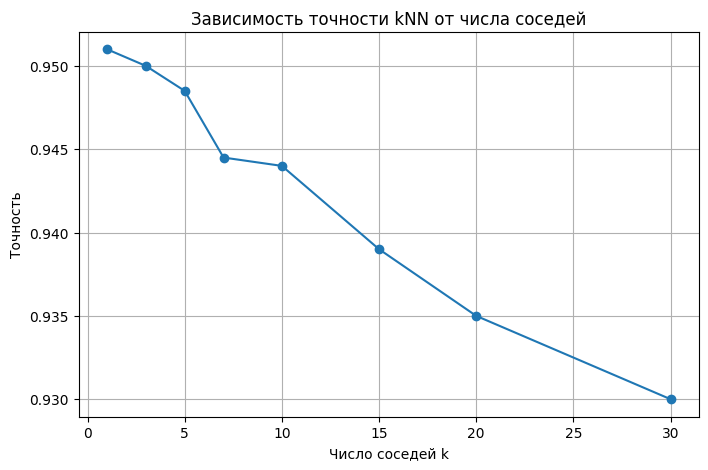

n_components=   1: accuracy=0.2500
n_components=   2: accuracy=0.4020
n_components=   5: accuracy=0.7060
n_components=  10: accuracy=0.9055
n_components=  15: accuracy=0.9475
n_components=  20: accuracy=0.9590
n_components=  30: accuracy=0.9620
n_components=  50: accuracy=0.9590
n_components=  75: accuracy=0.9560
n_components= 100: accuracy=0.9585
n_components= 200: accuracy=0.9510
n_components= 300: accuracy=0.9505
n_components= 500: accuracy=0.9485
n_components= 784: accuracy=0.9485


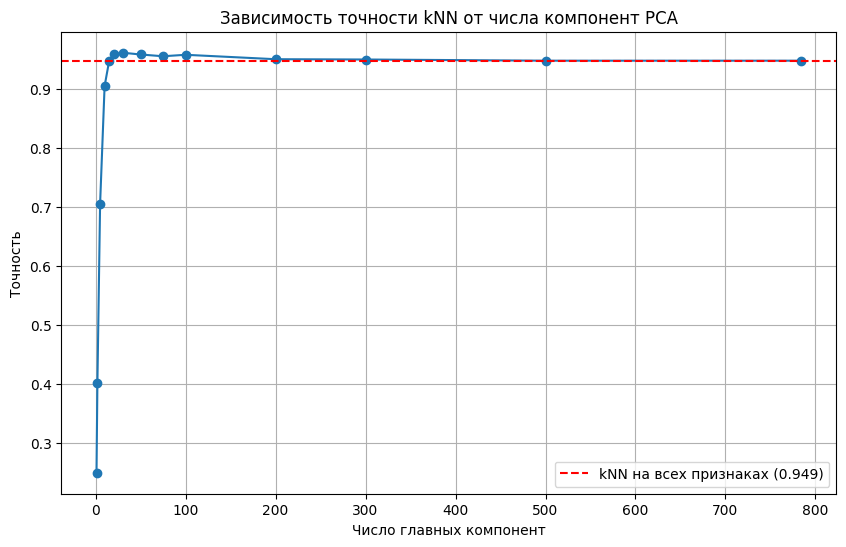

n_components=   1: 0.44 сек
n_components=   2: 0.20 сек
n_components=   5: 0.29 сек
n_components=  10: 0.29 сек
n_components=  15: 0.34 сек
n_components=  20: 0.32 сек
n_components=  30: 0.38 сек
n_components=  50: 0.54 сек
n_components=  75: 2.96 сек
n_components= 100: 0.77 сек
n_components= 200: 1.09 сек
n_components= 300: 3.08 сек
n_components= 500: 2.87 сек
n_components= 784: 6.67 сек


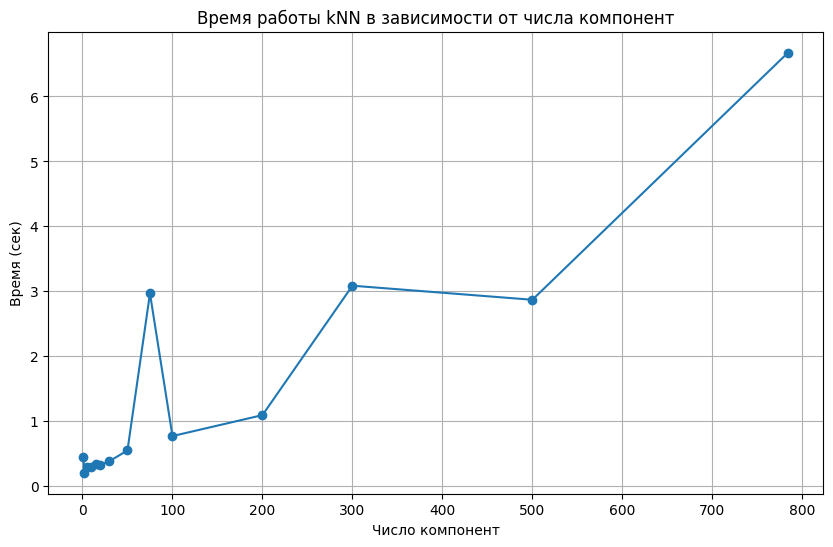

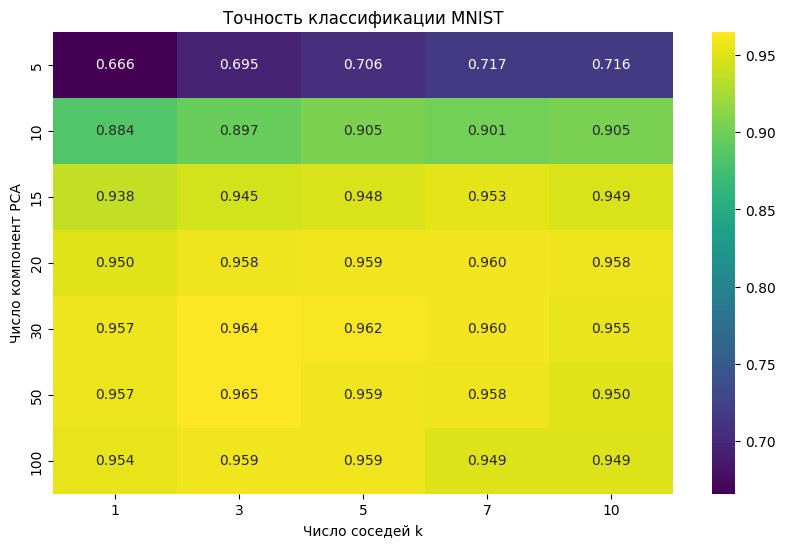

Лучшая комбинация: n_comp=50, k=3, acc=0.9650


In [6]:
#!pip install mnist

# ============================================================
# Лабораторная работа №2: PCA и kNN на MNIST
# ============================================================

# ---------- Часть 0. Подготовка данных ----------
import numpy as np
import matplotlib.pyplot as plt
#from mnist import load_mnist

import tensorflow as tf

def load_mnist():
    """Обёртка, возвращающая данные в формате (train, validation, test)."""
    (X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

    # Keras возвращает (n, 28, 28) — добавим ось канала, как ожидает ноутбук
    X_train_full = X_train_full[..., np.newaxis]   # (60000, 28, 28, 1)
    X_test = X_test[..., np.newaxis]               # (10000, 28, 28, 1)

    # Отделяем валидацию от обучения
    X_val, y_val = X_train_full[50000:], y_train_full[50000:]
    X_train = X_train_full[:50000],
    y_train = y_train_full[:50000]

    return (X_train[0], y_train), (X_val, y_val), (X_test, y_test)

train, validation, test = load_mnist()
X_train_full, y_train_full = train
X_val, y_val = validation
X_test, y_test = test

print(f"Размер обучающей выборки: {X_train_full.shape}")
print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

# Задание 0.2: визуализация примеров
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for digit in range(10):
    idx = np.where(y_train_full == digit)[0][0]
    ax = axes[digit // 5, digit % 5]
    ax.imshow(X_train_full[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f"Цифра {digit}")
    ax.axis('off')
plt.tight_layout()
plt.show()

# Задание 0.3: подготовка
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)
X = X.reshape(X.shape[0], -1)
X = X.astype(np.float32) / 255.0

print(f"Форма X: {X.shape}")
print(f"Форма y: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")

# ---------- Часть 1. PCA ----------

# Задание 1.1: реализация my_PCA
class my_PCA:
    def __init__(self, n_components=None):
        self.n_components = n_components
        self.components_ = None
        self.explained_variance_ = None
        self.mean_ = None

    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        X_centered = X - self.mean_
        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
        n_samples = X.shape[0]
        explained_variance = (S ** 2) / (n_samples - 1)
        self.components_ = Vt
        self.explained_variance_ = explained_variance
        if self.n_components is not None:
            self.components_ = self.components_[:self.n_components]
            self.explained_variance_ = self.explained_variance_[:self.n_components]
        return self

    def transform(self, X):
        X_centered = X - self.mean_
        return X_centered @ self.components_.T

    def fit_transform(self, X):
        return self.fit(X).transform(X)

# Задание 1.2: проверка реализации
from sklearn.decomposition import PCA

my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)
Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

print(f"Сумма собственных значений (my):      {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")
print(f"Форма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")
diff_abs = np.abs(np.abs(Y_my) - np.abs(Y_sk)).mean()
print(f"Средняя разница по абсолютным значениям: {diff_abs:.6f}")

# Задание 1.3: визуализация дисперсии
pca_full = my_PCA()
pca_full.fit(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(pca_full.explained_variance_, '.-')
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Собственное значение (дисперсия)')
axes[0].set_title('Спектр собственных значений')
axes[0].set_yscale('log')
axes[0].grid(True)

cumulative = np.cumsum(pca_full.explained_variance_)
cumulative /= cumulative[-1]
axes[1].plot(cumulative)
axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
axes[1].axhline(y=0.99, color='g', linestyle='--', label='99% дисперсии')
axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Доля объяснённой дисперсии')
axes[1].set_title('Кумулятивная дисперсия')
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

print(f"Доля дисперсии 15 компонент: {cumulative[14]:.4f}")
n95 = np.argmax(cumulative >= 0.95) + 1
n99 = np.argmax(cumulative >= 0.99) + 1
print(f"Компонент для 95%: {n95}")
print(f"Компонент для 99%: {n99}")

# Задание 1.4: визуализация в 2D
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

plt.figure(figsize=(10, 8))
for digit in range(10):
    mask = (y == digit)
    plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], label=str(digit), alpha=0.4, s=8)
plt.legend(markerscale=2)
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('MNIST в первых двух главных компонентах')
plt.grid(True)
plt.show()

# ---------- Часть 2. kNN ----------

# Задание 2.1: реализация my_kNN
class my_kNN:
    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        return self

    def predict(self, X):
        n_test = X.shape[0]
        y_pred = np.empty(n_test, dtype=self.y_train.dtype)
        X_train_sq = (self.X_train ** 2).sum(axis=1)
        X_test_sq = (X ** 2).sum(axis=1)
        for i in range(n_test):
            dists = X_train_sq + X_test_sq[i] - 2 * (self.X_train @ X[i])
            idx = np.argpartition(dists, self.n_neighbors)[:self.n_neighbors]
            labels = self.y_train[idx]
            y_pred[i] = np.bincount(labels).argmax()
        return y_pred

# Задание 2.2: проверка
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Уменьшим выборку для скорости
X_train_small = X_train[:10000]
y_train_small = y_train[:10000]
X_test_small = X_test[:2000]
y_test_small = y_test[:2000]

my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train_small, y_train_small)
y_pred_my = my_knn.predict(X_test_small)

accuracy_my = accuracy_score(y_test_small, y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f}")

# Задание 2.3: сравнение с sklearn
from sklearn.neighbors import KNeighborsClassifier

sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train_small, y_train_small)
y_pred_sk = sk_knn.predict(X_test_small)

accuracy_sk = accuracy_score(y_test_small, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")

# Задание 2.4: зависимость от k
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []
for k in k_values:
    knn = my_kNN(n_neighbors=k).fit(X_train_small, y_train_small)
    acc = accuracy_score(y_test_small, knn.predict(X_test_small))
    accuracies.append(acc)
    print(f"k={k:>3}: accuracy={acc:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, 'o-')
plt.xlabel('Число соседей k')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа соседей')
plt.grid(True)
plt.show()

# ---------- Часть 3. PCA + kNN ----------

# Задание 3.1: PCA перед kNN
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []
for n_comp in n_components_list:
    pca = my_PCA(n_components=n_comp)
    X_tr_p = pca.fit_transform(X_train_small)
    X_te_p = pca.transform(X_test_small)
    knn = my_kNN(n_neighbors=5).fit(X_tr_p, y_train_small)
    acc = accuracy_score(y_test_small, knn.predict(X_te_p))
    accuracies_pca.append(acc)
    print(f"n_components={n_comp:>4}: accuracy={acc:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(n_components_list, accuracies_pca, 'o-')
plt.axhline(y=accuracy_my, color='r', linestyle='--',
            label=f'kNN на всех признаках ({accuracy_my:.3f})')
plt.xlabel('Число главных компонент')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа компонент PCA')
plt.legend()
plt.grid(True)
plt.show()

# Задание 3.2: время работы
import time

times = []
for n_comp in n_components_list:
    pca = my_PCA(n_components=n_comp)
    X_tr_p = pca.fit_transform(X_train_small)
    X_te_p = pca.transform(X_test_small)
    start = time.time()
    knn = my_kNN(n_neighbors=5).fit(X_tr_p, y_train_small)
    knn.predict(X_te_p)
    times.append(time.time() - start)
    print(f"n_components={n_comp:>4}: {times[-1]:.2f} сек")

plt.figure(figsize=(10, 6))
plt.plot(n_components_list, times, 'o-')
plt.xlabel('Число компонент')
plt.ylabel('Время (сек)')
plt.title('Время работы kNN в зависимости от числа компонент')
plt.grid(True)
plt.show()

# Задание 3.3: сетка параметров
import seaborn as sns

n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]
accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

for i, n_comp in enumerate(n_components_grid):
    pca = my_PCA(n_components=n_comp)
    X_tr_p = pca.fit_transform(X_train_small)
    X_te_p = pca.transform(X_test_small)
    for j, k in enumerate(k_grid):
        knn = my_kNN(n_neighbors=k).fit(X_tr_p, y_train_small)
        accuracy_matrix[i, j] = accuracy_score(y_test_small, knn.predict(X_te_p))

plt.figure(figsize=(10, 6))
sns.heatmap(accuracy_matrix, annot=True, fmt='.3f',
            xticklabels=k_grid, yticklabels=n_components_grid,
            cmap='viridis')
plt.xlabel('Число соседей k')
plt.ylabel('Число компонент PCA')
plt.title('Точность классификации MNIST')
plt.show()

best = np.unravel_index(accuracy_matrix.argmax(), accuracy_matrix.shape)
print(f"Лучшая комбинация: n_comp={n_components_grid[best[0]]}, "
      f"k={k_grid[best[1]]}, acc={accuracy_matrix[best]:.4f}")
